## Laporan Analisis Eksploratif Ulasan Pemain GTA VI

### Executive Summary
Analisis deskriptif terhadap **51.385 ulasan pemain** menunjukkan bahwa penerimaan publik terhadap GTA VI terpolarisasi secara tajam ke dalam dua kutub ekstrem. Berikut adalah empat temuan utama dari evaluasi data:

* **Polarisasi Ekstrem atau Distribusi Bimodal:** Sebanyak **64.3%** dari keseluruhan ulasan menumpuk pada dua skor ekstrem, yakni **skor 10 sebanyak 18.097 ulasan** dan **skor 0 sebanyak 14.956 ulasan**, sehingga menghasilkan nilai rata-rata tepat di tengah pada angka **5.00** dengan median **4.0**. Secara keseluruhan, sentimen **Negatif pada skor 0 hingga 3 mencapai 46.5%**, sedikit melampaui sentimen **Positif pada skor 7 hingga 10 sebesar 43.8%**.
* **Ulasan Paling Kritis Berada di Skor Menengah:** Ulasan terpanjang justru ditulis oleh kelompok **Netral pada skor 4 hingga 6 dengan rata-rata 118.3 kata**, memuncak pada skor 6. Sebaliknya, ulasan pada skor 0 rata-rata hanya **63.7 kata** dan skor 10 hanya **59.0 kata**, menandakan bahwa skor ekstrem lebih banyak didominasi reaksi emosional singkat sementara skor menengah memuat evaluasi objektif yang menyeluruh.
* **Tiga Pemicu Utama Ketidakpuasan:** Pada kelompok skor 0, keluhan didominasi oleh ketidakpuasan terhadap **Gameplay sebesar 39.4%** dan **Cerita atau Story sebesar 32.4%**, diikuti oleh isu teknis **Performa atau FPS sebesar 22.1%**, **Harga atau Refund sebesar 21.2%**, **Bug atau Glitch sebesar 20.9%**, serta penolakan terhadap **Isu Sosial atau Woke sebesar 17.5%**.
* **Dukungan Kuat Komunitas Multibahasa:** Sebanyak **40.03%** ulasan mengandung karakter non-ASCII yang didominasi oleh pemain berbahasa Spanyol, Portugis, dan Italia. Proporsi ulasan non-ASCII terus meningkat dari **32.36% pada skor 0** menjadi **47.29% pada skor 10**, menunjukkan tingginya antusiasme pasar internasional terhadap atmosfer dunia Leonida dan Vice City.


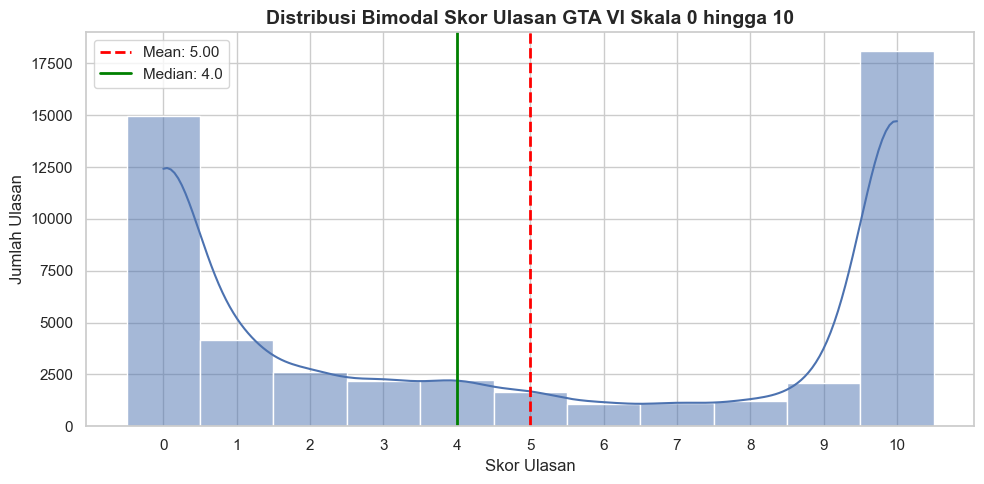

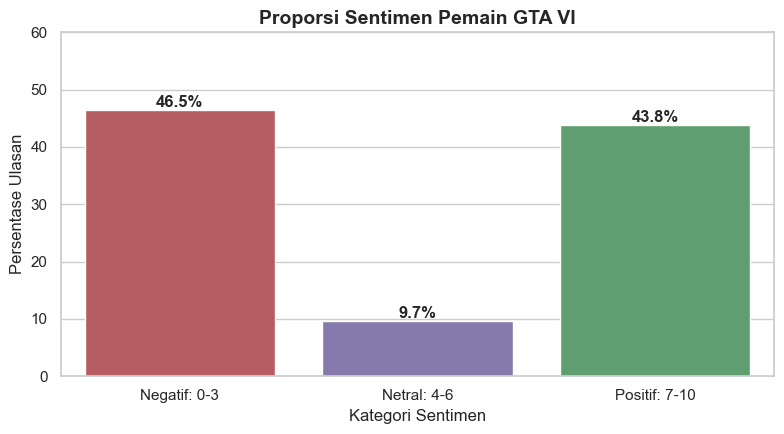

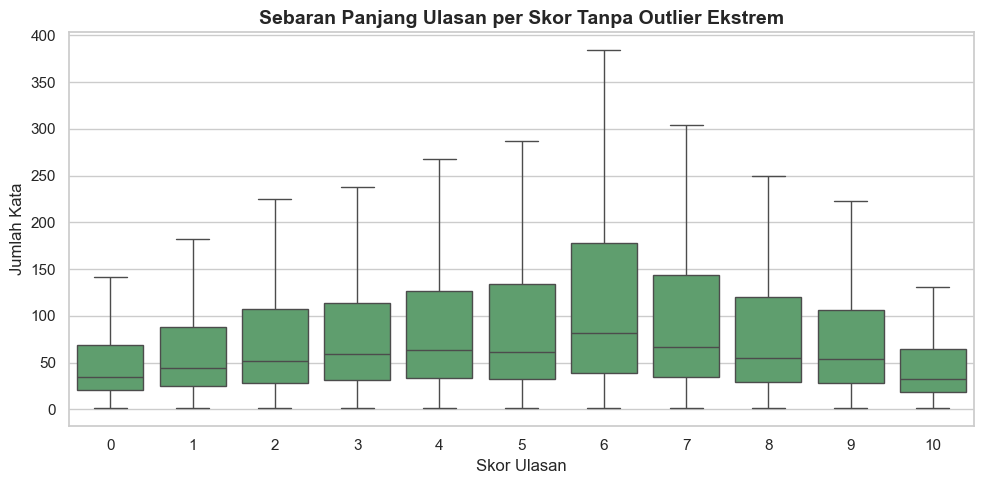

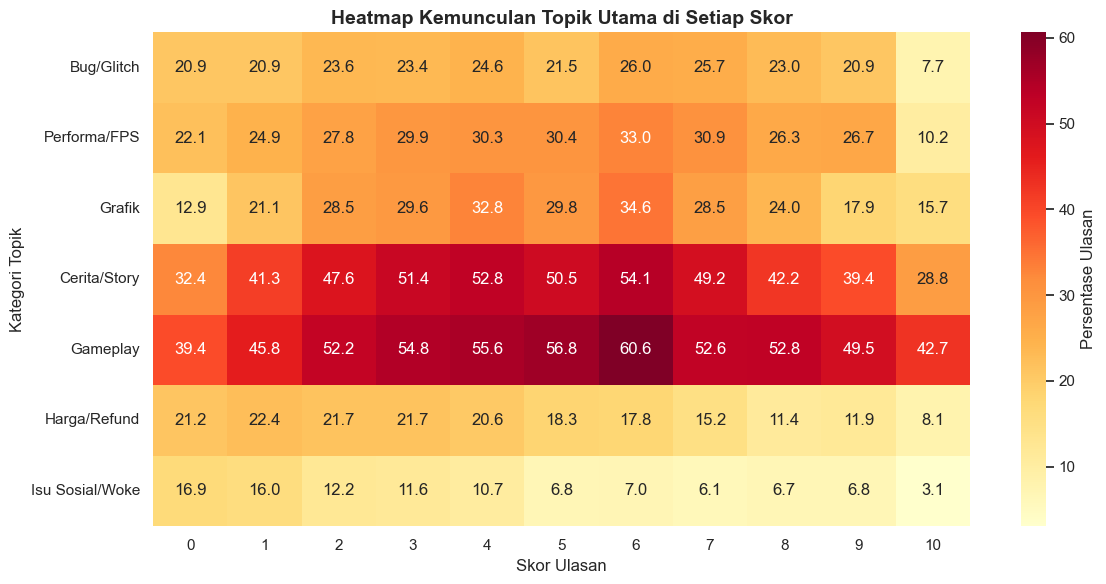

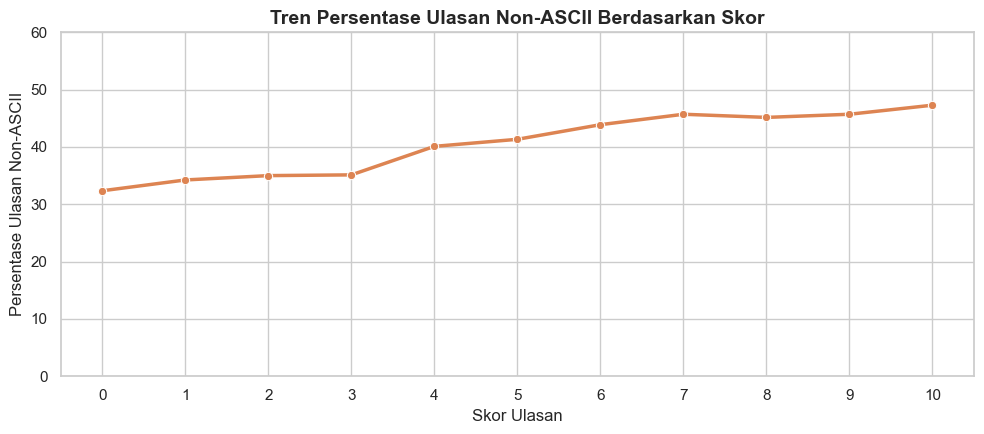

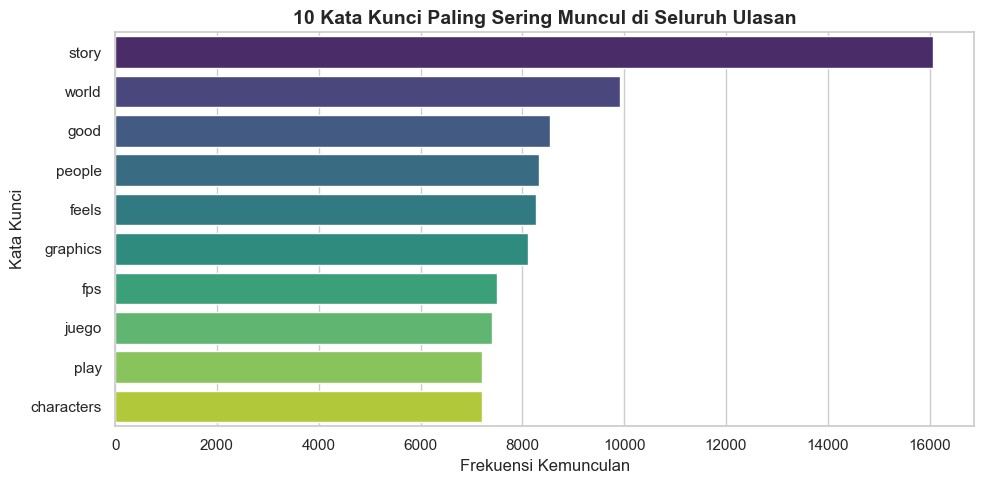

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")

# 1. Muat data & siapkan seluruh kolom fitur
df = pd.read_parquet('../data/processed/reviews_clean.parquet')
df['word_count'] = df['review_text'].str.split().str.len()
df['sentiment_group'] = pd.cut(df['score'], bins=[-1, 3, 6, 10], labels=['Negatif: 0-3', 'Netral: 4-6', 'Positif: 7-10'])
df['is_non_ascii'] = df['review_text'].str.contains(r'[^\x00-\x7F]', regex=True)

topik_keywords = {
    'Bug/Glitch': 'bug|glitch|crash|broken|freeze',
    'Performa/FPS': 'fps|lag|frame|stutter|optimize|performance',
    'Grafik': 'graphic|visual|texture|resolution',
    'Cerita/Story': 'story|plot|ending|character|mission',
    'Gameplay': 'gameplay|combat|driving|ai|control|mechanic',
    'Harga/Refund': 'price|money|refund|worth|pay|buy',
    'Isu Sosial/Woke': 'woke|agenda|politic'
}
for nama_topik, pattern in topik_keywords.items():
    df[nama_topik] = df['review_text'].str.contains(pattern, case=False, regex=True)

# --- GRAFIK 1: DISTRIBUSI SKOR ---
plt.figure(figsize=(10, 5))
ax = sns.histplot(df['score'], bins=11, kde=True, color='#4C72B0', discrete=True)
plt.axvline(df['score'].mean(), color='red', linestyle='--', linewidth=2, label=f"Mean: {df['score'].mean():.2f}")
plt.axvline(df['score'].median(), color='green', linestyle='-', linewidth=2, label=f"Median: {df['score'].median():.1f}")
plt.title('Distribusi Bimodal Skor Ulasan GTA VI Skala 0 hingga 10', fontsize=14, fontweight='bold')
plt.xlabel('Skor Ulasan')
plt.ylabel('Jumlah Ulasan')
plt.xticks(range(0, 11))
plt.legend()
plt.tight_layout()
plt.savefig('../images/01_distribusi_skor.png', dpi=300)
plt.show()

# --- GRAFIK 2: PROPORSI SENTIMEN ---
plt.figure(figsize=(8, 4.5))
urutan = ['Negatif: 0-3', 'Netral: 4-6', 'Positif: 7-10']
persen = (df['sentiment_group'].value_counts(normalize=True) * 100).reindex(urutan)
ax = sns.barplot(x=persen.index, y=persen.values, hue=persen.index, palette=['#C44E52', '#8172B3', '#55A868'], legend=False)
plt.title('Proporsi Sentimen Pemain GTA VI', fontsize=14, fontweight='bold')
plt.xlabel('Kategori Sentimen')
plt.ylabel('Persentase Ulasan')
plt.ylim(0, 60)
for p in ax.patches:
    ax.annotate(f"{p.get_height():.1f}%", (p.get_x() + p.get_width() / 2., p.get_height()), ha='center', va='bottom', fontweight='bold')
plt.tight_layout()
plt.savefig('../images/02_proporsi_sentimen.png', dpi=300)
plt.show()

# --- GRAFIK 3: BOXPLOT PANJANG KATA PER SKOR ---
plt.figure(figsize=(10, 5))
sns.boxplot(data=df, x='score', y='word_count', showfliers=False, color='#55A868')
plt.title('Sebaran Panjang Ulasan per Skor Tanpa Outlier Ekstrem', fontsize=14, fontweight='bold')
plt.xlabel('Skor Ulasan')
plt.ylabel('Jumlah Kata')
plt.tight_layout()
plt.savefig('../images/03_panjang_review_per_skor.png', dpi=300)
plt.show()

# --- GRAFIK 4: HEATMAP TOPIK VS SKOR ---
topik_cols = list(topik_keywords.keys())
heatmap_data = df.groupby('score')[topik_cols].mean() * 100
plt.figure(figsize=(12, 6))
sns.heatmap(heatmap_data.T, annot=True, fmt=".1f", cmap="YlOrRd", cbar_kws={'label': 'Persentase Ulasan'})
plt.title('Heatmap Kemunculan Topik Utama di Setiap Skor', fontsize=14, fontweight='bold')
plt.xlabel('Skor Ulasan')
plt.ylabel('Kategori Topik')
plt.tight_layout()
plt.savefig('../images/04_heatmap_topik_skor.png', dpi=300)
plt.show()

# --- GRAFIK 5: PROPORSI NON-ASCII PER SKOR ---
non_ascii_skor = pd.crosstab(df['score'], df['is_non_ascii'], normalize='index')[True] * 100
plt.figure(figsize=(10, 4.5))
sns.lineplot(x=non_ascii_skor.index, y=non_ascii_skor.values, marker='o', linewidth=2.5, color='#DD8452')
plt.title('Tren Persentase Ulasan Non-ASCII Berdasarkan Skor', fontsize=14, fontweight='bold')
plt.xlabel('Skor Ulasan')
plt.ylabel('Persentase Ulasan Non-ASCII')
plt.xticks(range(0, 11))
plt.ylim(0, 60)
plt.tight_layout()
plt.savefig('../images/05_tren_non_ascii.png', dpi=300)
plt.show()

# --- GRAFIK 6: TOP 10 KATA DOMINAN ---
stopwords = {
    'the', 'and', 'to', 'of', 'a', 'is', 'in', 'it', 'this', 'for', 'game', 'gta', 'rockstar', 'games',
    'i', 'that', 'with', 'on', 'was', 'but', 'as', 'are', 'have', 'be', 'not', 'you', 'they', 'so',
    'all', 'its', 'my', 'just', 'like', 'one', 'at', 'from', 'que', 'what', 'has', 'more', 'even', 'dont', 'can', 'about'
}
kata_bersih = df['review_text'].str.lower().str.replace(r'[^\w\s]', '', regex=True).str.split().explode()
top10_kata = kata_bersih[~kata_bersih.isin(stopwords) & (kata_bersih.str.len() > 2)].value_counts().head(10)

plt.figure(figsize=(10, 5))
sns.barplot(x=top10_kata.values, y=top10_kata.index, hue=top10_kata.index, palette='viridis', legend=False)
plt.title('10 Kata Kunci Paling Sering Muncul di Seluruh Ulasan', fontsize=14, fontweight='bold')
plt.xlabel('Frekuensi Kemunculan')
plt.ylabel('Kata Kunci')
plt.tight_layout()
plt.savefig('../images/06_top10_kata.png', dpi=300)
plt.show()

## Rekomendasi Actionable untuk Rockstar dan Stakeholder

1. **Prioritas Perbaikan Performa Teknis dan Stabilitas FPS:** Tim pengembangan harus memprioritaskan optimalisasi *frame rate* serta perbaikan *bug* atau *crash*, karena **22.1% ulasan skor 0** mengeluhkan masalah performa dan **20.9%** menyoroti *bug*, angka yang lebih dari dua kali lipat dibandingkan kelompok skor 10.
2. **Evaluasi Desain Misi dan Mekanik Gameplay pada Fase Awal Permainan:** Mengingat **39.4% ulasan skor 0** mengkritik aspek *gameplay* dan sampel ulasan menyoroti lambatnya alur misi pembuka, tim desainer perlu meninjau ulang tempo *pacing* dan variasi aktivitas di jam-jam awal permainan agar pemain tidak cepat merasa bosan.
3. **Jadikan Ulasan Skor Menengah sebagai Sumber Utama Masukan Pengembangan:** Tim riset pengguna disarankan untuk memfokuskan analisis kualitatif pada **ulasan skor 4 hingga 7** yang memiliki rata-rata panjang di atas **100 kata**, karena kelompok ini memberikan kritik konstruktif yang paling seimbang dibandingkan ulasan emosional pada skor 0 atau 10.
4. **Pertahankan Dukungan Lokalisasi dan Komunitas Pasar Internasional:** Tingginya proporsi ulasan non-ASCII pada **skor 10 sebesar 47.3%** membuktikan bahwa pasar berbahasa Spanyol, Portugis, dan Italia merupakan basis pendukung terkuat, sehingga kualitas terjemahan serta infrastruktur server di wilayah tersebut perlu terus dipertahankan.